> **AI for RO · the lab study: a model that follows the pump** — part of Project 3 of [chemai](https://github.com/EngMtaleb/chemai/tree/main/projects/p03_ai_for_ro). This notebook was written as “phase 1”: its code, its printed lines and the declaration appended at the end keep the names they were written with. Working names → the episode: phase 3 → **phase 1**, phase 3b → **phase 1B**, phase 4 → **phase 3**, phase 1 → **the lab study**; phase 2 keeps its number.

# RO performance when pressure and flow change — the lab study

**Question:** if the high-pressure pump follows the power that is available (the sun, later), pressure and flow keep changing.
How much permeate do we get, and how salty is it?

**Data:** public tests on one seawater element (SW30-4040, 7.4 m²), NaCl in dechlorinated tap water (35–40 g/L), about 20 °C,
logged every 0.25 s — steady pressures, ramps, sine waves and two sea-wave profiles. MHKDR submission 649 (CC BY 4.0);
paper: Sitterley, Binger & Jenne (2025), *Membranes* 15(8) 243, [doi:10.3390/membranes15080243](https://doi.org/10.3390/membranes15080243).

**What the data does not have:** pump power (not measured), other temperatures (all ~20 °C), fouling (clean salt water),
start-up and shut-down (removed from the files).

**Four models, from simple to combined:**
1. **Steady-state curve** — the five steady-state points, read off by feed pressure (an operator's chart).
2. **Physics** — solution–diffusion with constant water and salt permeability (A, B), fitted on the steady state only.
3. **XGBoost** — learns from the measurements.
4. **Hybrid** — the physics, plus XGBoost trained on the physics error.

**The honest test:** train on the steady-state and ramp runs; test on runs the models never saw —
sine runs from 500 psi up and the two sea-wave runs (*in range*), and sine runs that drop to 250–350 psi (*below range*).

**A second look (sections 10–13),** after reading the Smart RO study of the same public tests: its data checks on the raw rows,
the whole study again with the feed gauge alone, our models scored on Smart RO's own split and units, and the delay of the
conductivity sensor. The code and results of sections 1–9 are unchanged.

In [1]:
# Colab: the libraries are already there (pandas, numpy, xgboost, matplotlib)
import glob, hashlib, io, urllib.request, zipfile
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from xgboost import XGBRegressor

## 1 · Download the four data files and check them

The data page publishes no checksum, so each file is checked against the SHA-256 of the copy used for this analysis (downloaded 28 October 2026).

In [2]:
BASE = "https://mhkdr.openei.org/files/649/"
FILES = {"steady_state": ("steady_state.zip", "12d4cebcb29e2eb992b51e87717ba35ac526d440fe3f210bca6f064208ced7e6"),
         "ramp":         ("ramp.zip",         "7457eb94d0fa5829c431a0d967e3b8951eab778bc6a9e97c5f661a461f669c1a"),
         "sine":         ("sine.zip",         "9a9d375c85ef6ab33a1313ea5989d4d0dc095b65d2317c122fc5893d817ec2fd"),
         "wec_sim":      ("wec_sim%20(1).zip", "423d34f0749a22ab91f4045587454f8641f43e5de34685dc5a1871a460169ead")}
D = Path("data")
for group, (name, sha) in FILES.items():
    if (D / group).exists():
        continue
    req = urllib.request.Request(BASE + name, headers={"User-Agent": "Mozilla/5.0"})
    raw = urllib.request.urlopen(req, timeout=180).read()
    assert hashlib.sha256(raw).hexdigest() == sha, f"{name}: not the file used for this analysis"
    zipfile.ZipFile(io.BytesIO(raw)).extractall(D / group)
print(sorted(Path(p).name for p in glob.glob(str(D / "*" / "*" / "*.csv")) if "__MACOSX" not in p)[:6], "...")

['ramp_dp_100.csv', 'ramp_dp_200.csv', 'ramp_dp_300.csv', 'ramp_dp_400.csv', 'sine_250-650psi_10s_period.csv', 'sine_250-650psi_20s_period.csv'] ...


## 2 · From quarter-seconds to one-second rows

Each experiment is averaged to 1-second rows. Then, in plain terms:
- salinity from conductivity: **c = 0.6638 × κ** (g/L per mS/cm — the rig's own calibration, from the README)
- **flux** = permeate flow ÷ 7.4 m² (LMH)
- **salt flow** = permeate salinity × permeate flow (mg/min) — so a run's product salinity is *all the salt ÷ all the water*
- pressure across the membrane = the average of the feed and reject gauges (the paper's choice). Note: at steady state the reject
  gauge reads 7–22 psi *above* the feed gauge, which cannot happen along one element. The gap grows with pressure, so it is not a
  fixed offset, and its cause is not known (section 10). Section 11 runs the whole study again with the feed gauge alone.

In [3]:
AREA, K_SAL, PSI_PER_BAR = 7.4, 0.6638, 14.5038
LOW_MIN_PSI, FLUX_MIN, SEEDS = 480, 1.0, [0, 1, 2, 3, 4]
COLS = {"Feed Pressure (psi)": "p_f", "Reject Pressure (psi)": "p_b", "Feed Flowrate (L/min)": "q_f",
        "Permeate 1 Flowrate (L/min)": "q_p", "Reject Flowrate (L/min)": "q_b",
        "Feed Conductivity (mS/cm)": "k_f", "Permeate 1 Conductivity (uS/cm)": "k_p",
        "Reject Conductivity (mS/cm)": "k_b", "Feed Temperature (C)": "temp"}

def load(root=D):
    parts = []
    for f in sorted(glob.glob(str(Path(root) / "*" / "*" / "*.csv"))):
        if "__MACOSX" in f:
            continue
        group = Path(f).parent.name
        d = pd.read_csv(f)
        seg_col = {"steady_state": "Steady-State Pressure (psi)", "ramp": "dt (s)"}.get(group)   # one experiment each
        x = d.rename(columns=COLS)[list(COLS.values())].copy()
        x["group"], x["file"] = group, Path(f).stem
        x["seg"] = x.file + "|" + (d[seg_col].astype(str) if seg_col else "all")
        x["t"] = d["Index"].to_numpy() * 0.25
        parts.append(x)
    raw = pd.concat(parts, ignore_index=True)
    raw["sec"] = np.floor(raw.t - raw.groupby("seg").t.transform("min")).astype(int)
    g = raw.groupby(["group", "file", "seg", "sec"], sort=False)
    x = g[list(COLS.values())].mean()
    x["n"] = g.size()
    x = x[x.n == 4].reset_index()                          # complete seconds only
    x["c_f"] = K_SAL * x.k_f                                # g/L
    x["c_p"] = K_SAL * x.k_p                                # mg/L
    x["flux"] = x.q_p * 60 / AREA                           # LMH
    x["S"] = x.c_p * x.q_p                                  # salt flow, mg/min
    x["dP"] = (x.p_f + x.p_b) / 2                           # psi
    for w in (5, 15, 30, 60):                               # the recent pressure (past seconds only)
        x[f"p_f_mean{w}"] = x.groupby("seg").p_f.transform(lambda s: s.rolling(w, min_periods=1).mean())
    for lag in (5, 15):
        x[f"p_f_change{lag}"] = x.p_f - x.groupby("seg").p_f.shift(lag)
    x["split"] = np.where(x.group.isin(["steady_state", "ramp"]), "train", "test_in")
    trough = x.file.str.extract(r"sine_(\d+)-")[0].astype(float)
    x.loc[(x.group == "sine") & (trough < LOW_MIN_PSI), "split"] = "test_low"
    return x

x = load()
print(x.split.value_counts().to_dict(), "one-second rows")
x.groupby("group").agg(runs=("file", "nunique"), minutes=("sec", lambda s: len(s) / 60), p_min=("p_f", "min"), p_max=("p_f", "max"),
                       feed_gL=("c_f", "median"), temp_C=("temp", "median")).round(1)

{'train': 43949, 'test_in': 12795, 'test_low': 3247} one-second rows


,runs,minutes,p_min,p_max,feed_gL,temp_C
group,,,,,,
ramp,4,707.5,490.6,909.4,35.5,20.0
sine,23,115.7,248.2,909.1,35.0,20.1
steady_state,1,25.0,499.1,901.1,39.5,20.0
wec_sim,2,151.6,510.1,844.7,36.9,20.0


## 3 · Look first: the four kinds of test (pressure and permeate flow)

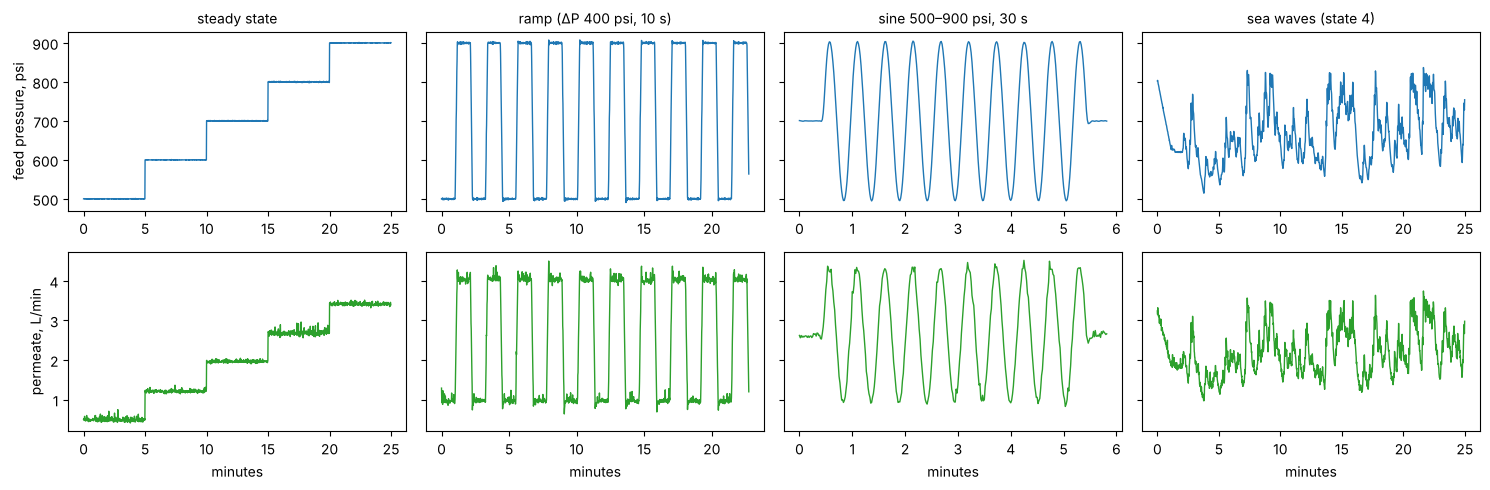

In [4]:
show = {"steady state": ("steady_state", None), "ramp (ΔP 400 psi, 10 s)": ("ramp_dp_400", "ramp_dp_400|10"),
        "sine 500–900 psi, 30 s": ("sine_500-900psi_30s_period", None), "sea waves (state 4)": ("wec_sim_ss4", None)}
fig, axes = plt.subplots(2, 4, figsize=(15, 5), sharey="row")
for j, (title, (f, seg)) in enumerate(show.items()):
    g = x[(x.file == f) & ((x.seg == seg) if seg else True)].head(1500)
    axes[0, j].plot(np.arange(len(g)) / 60, g.p_f, lw=1); axes[0, j].set_title(title, fontsize=10)
    axes[1, j].plot(np.arange(len(g)) / 60, g.q_p, lw=1, color="tab:green"); axes[1, j].set_xlabel("minutes")
axes[0, 0].set_ylabel("feed pressure, psi"); axes[1, 0].set_ylabel("permeate, L/min"); plt.tight_layout()

## 4 · The physics: solution–diffusion with constant A and B

The paper's constant-parameter form (its equations 3 and 19–24), fitted on the five steady-state runs only:
- osmotic pressure of NaCl: π = 0.741829 c + 0.00111004 c² (bar, c in g/L)
- average feed-side concentration factor: f(Y) = [−ln(1−Y)/Y] · exp(0.7 Y), with recovery Y = permeate ÷ feed
- **water:** J = A (ΔP − f(Y) π_feed) — zero below the osmotic pressure
- **salt:** salt flux = B · c_feed · f(Y)

The physics uses the feed flow only through the recovery term.

In [5]:
def pi_psi(c):
    return (0.741829 * c + 0.00111004 * c ** 2) * PSI_PER_BAR

def fy(Y):
    Y = np.clip(Y, 1e-6, 0.99)
    return -np.log(1 - Y) / Y * np.exp(0.7 * Y)

def fit_physics(x):
    s = x[x.group == "steady_state"]
    Y = s.q_p / s.q_f
    ndp = s.dP - fy(Y) * pi_psi(s.c_f)
    A = float((s.flux * ndp).sum() / (ndp ** 2).sum())
    z = s.c_f * fy(Y) / s.flux
    B = float(((s.c_p / 1000) * z).sum() / (z ** 2).sum())
    return A, B

def predict_physics(x, A, B, iters=60):
    """Solve J = A (dP - fy(Y) pi_f), Y = J AREA / (60 q_f), by bisection. Returns permeate L/min and salt mg/min."""
    dP, q_f, pif, c_f = x.dP.to_numpy(), x.q_f.to_numpy(), pi_psi(x.c_f.to_numpy()), x.c_f.to_numpy()
    lo, hi = np.zeros(len(x)), np.maximum(A * dP, 0)
    for _ in range(iters):
        J = (lo + hi) / 2
        g = J - A * (dP - fy(J * AREA / (60 * q_f)) * pif)
        hi, lo = np.where(g > 0, J, hi), np.where(g > 0, lo, J)
    J = (lo + hi) / 2
    J[A * (dP - pif) <= 0] = 0.0
    S = np.where(J > 0, 1000 * B * c_f * fy(J * AREA / (60 * q_f)) * AREA / 60, 0.0)
    return J * AREA / 60, S

A, B = fit_physics(x)
print(f"A = {A:.4f} LMH/psi ({A * PSI_PER_BAR:.3f} LMH/bar) · B = {B:.4f} LMH  (fitted on the steady state only)")

A = 0.0756 LMH/psi (1.097 LMH/bar) · B = 0.0773 LMH  (fitted on the steady state only)


## 5 · The four models

The ML inputs are the **pressures, their recent history, feed salinity and temperature — no flows**. The brine valve is fixed
(5 % open in every run), so feed flow plus pressure would give away the permeate flow by a mass balance
(permeate = feed − what the valve passes at that pressure). That is true of this rig only, not of a plant.

In [6]:
FEATS = ["p_f", "p_b", "c_f", "temp"] + [f"p_f_mean{w}" for w in (5, 15, 30, 60)] + ["p_f_change5", "p_f_change15"]
Q_FLOOR = 0.12                                              # L/min (1 LMH)

def xgb(seed):
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                        min_child_weight=10, random_state=seed, n_jobs=4, verbosity=0)

def steady_curve(x):
    s = x[x.group == "steady_state"]
    if s.empty:
        return lambda d: (np.full(len(d), np.nan), np.full(len(d), np.nan))
    s = s.groupby("seg").agg(p=("p_f", "mean"), q=("q_p", "mean"), S=("S", "mean")).sort_values("p")
    return lambda d: (np.interp(d.p_f, s.p, s.q), np.interp(d.p_f, s.p, s.S))

def fit_predict(x, tr, te, A, B, seed=0):
    """(permeate L/min, salt mg/min) of the four models on rows te, trained on rows tr."""
    curve = steady_curve(x.iloc[tr])
    qph, Sph = predict_physics(x, A, B)
    X = x[FEATS].to_numpy(); Xh = np.column_stack([X, qph, Sph])
    q, S = x.q_p.to_numpy(), x.S.to_numpy()
    out = {"steady-state curve": curve(x.iloc[te]), "physics": (qph[te], Sph[te])}
    out["XGBoost"] = (xgb(seed).fit(X[tr], q[tr]).predict(X[te]), xgb(seed).fit(X[tr], S[tr]).predict(X[te]))
    out["hybrid"] = (qph[te] + xgb(seed).fit(Xh[tr], (q - qph)[tr]).predict(Xh[te]),
                     Sph[te] + xgb(seed).fit(Xh[tr], (S - Sph)[tr]).predict(Xh[te]))
    return {m: (np.maximum(np.asarray(a, float), 0), np.maximum(np.asarray(b, float), 0)) for m, (a, b) in out.items()}

def salinity(q, S):
    return S / np.maximum(q, Q_FLOOR)

def scores(x, te, preds):
    """Second by second, and run by run (total water; product salinity = all the salt / all the water)."""
    d = x.iloc[te]; prod = (d.flux >= FLUX_MIN).to_numpy(); res = {}
    for m, (qp, Sp) in preds.items():
        cp = salinity(qp, Sp)
        runs = pd.DataFrame([dict(run=f, water_err_pct=100 * (g.qp.sum() / g.q_p.sum() - 1),
                                  salinity_err_pct=100 * ((g.Sp.sum() / max(g.qp.sum(), 1e-9)) / (g.S.sum() / g.q_p.sum()) - 1))
                             for f, g in d.assign(qp=qp, Sp=Sp).groupby("file")])
        res[m] = {"water error, % (per second)": 100 * np.mean(np.abs(qp - d.q_p)) / d.q_p.mean(),
                  "salinity error, mg/L (per second)": np.mean(np.abs(cp[prod] - d.c_p.to_numpy()[prod])),
                  "run water error, median |%|": runs.water_err_pct.abs().median(),
                  "run salinity error, median |%|": runs.salinity_err_pct.abs().median(), "runs": runs}
    return res

tr = np.where(x.split == "train")[0]
results, test_preds = {}, {}
for split in ("test_in", "test_low"):
    te = np.where(x.split == split)[0]
    runs = [fit_predict(x, tr, te, A, B, seed) for seed in SEEDS]          # five seeds, averaged
    test_preds[split] = {m: (np.mean([r[m][0] for r in runs], axis=0), np.mean([r[m][1] for r in runs], axis=0)) for m in runs[0]}
    results[split] = scores(x, te, test_preds[split])
print("done")

done


## 6 · The honest test: runs the models never saw

### 6a · In range — sine runs from 500 psi up, and the two sea-wave runs (15 runs)

In [7]:
table = lambda split: pd.DataFrame({m: {k: v for k, v in r.items() if k != "runs"} for m, r in results[split].items()}).T.round(1)
table("test_in")

,"water error, % (per second)","salinity error, mg/L (per second)","run water error, median |%|","run salinity error, median |%|"
steady-state curve,20.4,64.4,23.6,48.2
physics,10.4,72.4,9.0,6.9
XGBoost,9.5,40.7,4.9,10.9
hybrid,4.2,53.6,4.7,11.5


### 6b · Below range — sine runs that drop to 250–350 psi, lower than anything in training (10 runs)

In [8]:
table("test_low")

,"water error, % (per second)","salinity error, mg/L (per second)","run water error, median |%|","run salinity error, median |%|"
steady-state curve,50.2,235.6,27.0,31.9
physics,32.8,379.8,34.6,17.3
XGBoost,46.7,102.7,36.7,18.9
hybrid,13.6,189.0,1.8,17.4


## 7 · Run by run — the numbers that matter for planning

Error of each run's **total water** and **product salinity**, % (predicted ÷ measured − 1).

In [9]:
for split, title in (("test_in", "in range"), ("test_low", "below range")):
    t = pd.concat({m: results[split][m]["runs"].set_index("run")[["water_err_pct", "salinity_err_pct"]] for m in ("physics", "XGBoost", "hybrid")}, axis=1)
    t.index = t.index.str.replace("sine_", "").str.replace("psi_", " psi ").str.replace("_period", "")
    print(title); display(t.round(1))

in range


physics                        XGBoost                   \
                water_err_pct salinity_err_pct water_err_pct salinity_err_pct   
run                                                                             
500-900 psi 10s         -11.3             -6.9          -6.0              7.4   
500-900 psi 20s         -11.9             -5.5          -5.9              3.5   
500-900 psi 30s         -10.2             -1.8          -5.4             16.9   
500-900 psi 60s         -10.3             -5.3          -5.5             10.4   
550-900 psi 10s         -13.0             -9.0          -6.7              7.3   
600-900 psi 10s          -8.2             -4.4          -4.8             11.5   
600-900 psi 20s          -8.3             -4.2          -4.9             11.1   
600-900 psi 30s          -9.0             -5.1          -4.5             12.3   
600-900 psi 60s          -8.8             -5.5          -4.7             12.3   
700-900 psi 10s          -7.9             -9.4          -4.7             12.3   
700-900 psi 20s          -6.7             -8.1          -4.9             10.9   
700-900 psi 30s          -7.7             -8.9          -4.2              8.8   
700-900 psi 60s          -8.0             -9.4          -4.9             10.6   
wec_sim_ss4             -12.9            -31.2          -8.7            -19.7   
wec_sim_ss6              -9.4            -33.0         -12.9            -10.6   

                       hybrid                   
                water_err_pct salinity_err_pct  
run                                             
500-900 psi 10s          -5.3              8.1  
500-900 psi 20s          -4.8              3.5  
500-900 psi 30s          -4.6             15.4  
500-900 psi 60s          -4.9              9.0  
550-900 psi 10s          -5.6              6.8  
600-900 psi 10s          -5.0             12.5  
600-900 psi 20s          -5.7             13.3  
600-900 psi 30s          -4.1             11.0  
600-900 psi 60s          -4.3             12.4  
700-900 psi 10s          -4.5             12.1  
700-900 psi 20s          -5.0             11.5  
700-900 psi 30s          -4.3              9.1  
700-900 psi 60s          -4.7             11.0  
wec_sim_ss4              -2.9            -26.4  
wec_sim_ss6              -3.9            -21.1

below range


physics                        XGBoost                   \
                water_err_pct salinity_err_pct water_err_pct salinity_err_pct   
run                                                                             
250-650 psi 10s         -42.2            -23.1          11.0            -30.8   
250-650 psi 20s         -36.8            -28.3          23.1            -32.2   
250-650 psi 30s         -33.5            -26.2          30.0            -16.2   
250-650 psi 60s         -28.7            -21.0          36.1            -18.5   
300-600 psi 10s         -39.4             -3.2          27.0            -17.4   
300-600 psi 20s         -35.6            -13.8          37.4            -30.9   
300-600 psi 30s         -33.2            -12.7          40.4            -18.9   
300-600 psi 60s         -30.4            -11.3          44.4            -22.1   
350-550 psi 30s         -36.2             20.6          58.4            -18.9   
350-550 psi 60s         -33.0             13.9          52.9            -18.3   

                       hybrid                   
                water_err_pct salinity_err_pct  
run                                             
250-650 psi 10s         -19.4            -29.8  
250-650 psi 20s          -9.1            -37.4  
250-650 psi 30s          -4.7            -15.0  
250-650 psi 60s          -1.9            -18.5  
300-600 psi 10s          -9.4            -16.2  
300-600 psi 20s          -0.6            -37.4  
300-600 psi 30s          -1.1            -15.3  
300-600 psi 60s          -1.7            -19.0  
350-550 psi 30s           1.7             -9.1  
350-550 psi 60s          -1.1            -10.0

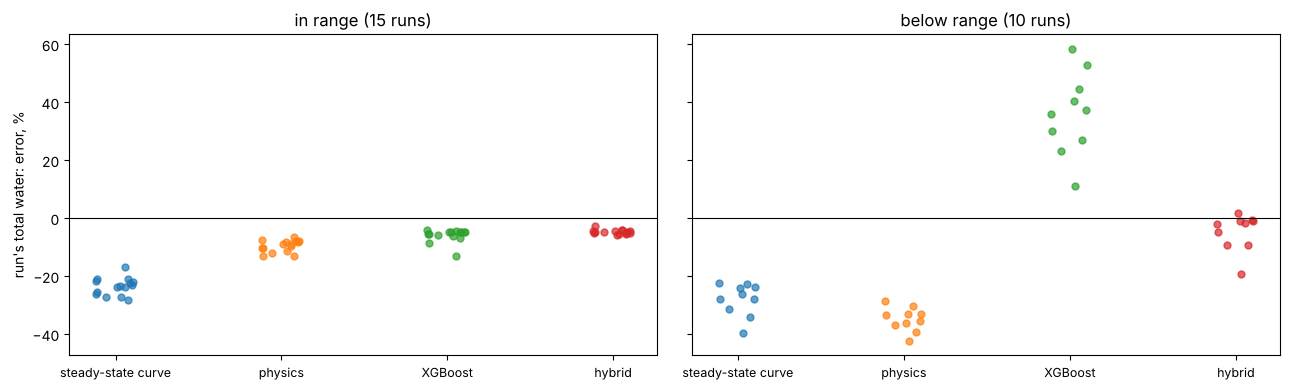

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
models = ["steady-state curve", "physics", "XGBoost", "hybrid"]
for ax, (split, title) in zip(axes, (("test_in", "in range (15 runs)"), ("test_low", "below range (10 runs)"))):
    for i, m in enumerate(models):
        e = results[split][m]["runs"].water_err_pct
        ax.plot(np.full(len(e), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(e)), e, "o", ms=5, alpha=0.7)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(4)); ax.set_xticklabels(models, fontsize=9); ax.set_title(title)
axes[0].set_ylabel("run's total water: error, %"); plt.tight_layout()

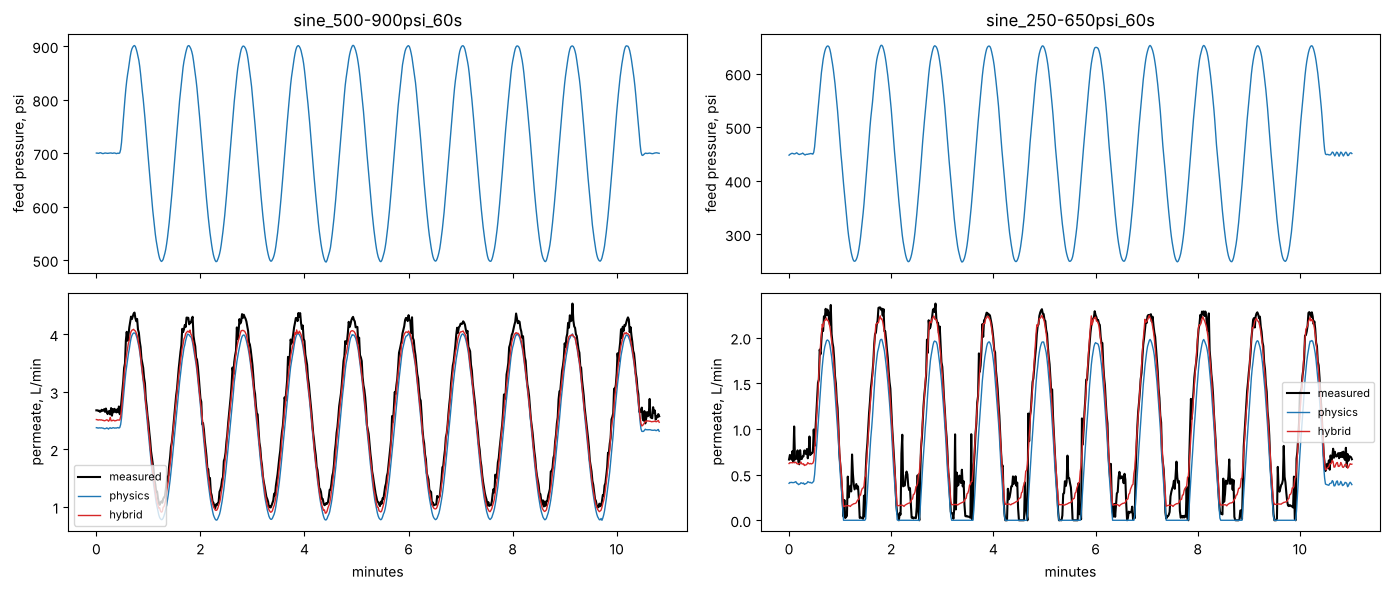

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex="col")
for j, f in enumerate(["sine_500-900psi_60s_period", "sine_250-650psi_60s_period"]):
    split = "test_in" if "500" in f else "test_low"
    te = np.where(x.split == split)[0]; d = x.iloc[te]; k = (d.file == f).to_numpy(); t = np.arange(k.sum()) / 60
    axes[0, j].plot(t, d.p_f[k], lw=1); axes[0, j].set_title(f.replace("_period", "")); axes[0, j].set_ylabel("feed pressure, psi")
    axes[1, j].plot(t, d.q_p[k], "k", lw=1.5, label="measured")
    for m, c in (("physics", "tab:blue"), ("hybrid", "tab:red")):
        axes[1, j].plot(t, test_preds[split][m][0][k], lw=1, color=c, label=m)
    axes[1, j].set_ylabel("permeate, L/min"); axes[1, j].set_xlabel("minutes"); axes[1, j].legend(fontsize=8)
plt.tight_layout()

## 8 · The uncertainty range — and whether it holds

Each training experiment is predicted by a model that never saw its file; 90 % of those run errors fall inside the range below.
Then: how many of the unseen test runs fall inside it?

In [12]:
def run_bands(x, A, B, tr_idx):
    tr_ = x.iloc[tr_idx]; errs = {m: {"water": [], "salinity": []} for m in ("physics", "XGBoost", "hybrid")}
    for f in tr_.file.unique():
        te_f, tr_f = tr_idx[tr_.file.to_numpy() == f], tr_idx[tr_.file.to_numpy() != f]
        p = fit_predict(x, tr_f, te_f, A, B); d = x.iloc[te_f]
        for m in errs:
            if m == "physics" and f.startswith("steady"):
                continue                                    # the physics was fitted on the steady state
            qp, Sp = p[m]
            for seg, g in d.assign(qp=qp, Sp=Sp).groupby("seg"):
                errs[m]["water"].append(100 * (g.qp.sum() / g.q_p.sum() - 1))
                errs[m]["salinity"].append(100 * ((g.Sp.sum() / g.qp.sum()) / (g.S.sum() / g.q_p.sum()) - 1))
    return {m: {k: float(np.quantile(np.abs(v), 0.9)) for k, v in e.items()} for m, e in errs.items()}

rb = run_bands(x, A, B, tr)
rows = {}
for m, b in rb.items():
    r = {"expected water range, ±%": b["water"], "expected salinity range, ±%": b["salinity"]}
    for split, name in (("test_in", "in range"), ("test_low", "below range")):
        runs = results[split][m]["runs"]
        r[f"water runs inside, % ({name})"] = 100 * (runs.water_err_pct.abs() <= b["water"]).mean()
        r[f"salinity runs inside, % ({name})"] = 100 * (runs.salinity_err_pct.abs() <= b["salinity"]).mean()
    rows[m] = r
pd.DataFrame(rows).T.round(1)

,"expected water range, ±%","expected salinity range, ±%","water runs inside, % (in range)","salinity runs inside, % (in range)","water runs inside, % (below range)","salinity runs inside, % (below range)"
physics,6.7,17.2,6.7,86.7,0.0,50.0
XGBoost,9.6,10.0,93.3,26.7,0.0,0.0
hybrid,1.8,6.9,0.0,13.3,50.0,0.0


## 9 · The random-split trap, once more — the same XGBoost, scored on a random 30 % of all seconds

In [13]:
def xgb_only(x, tr, te, seed):
    X = x[FEATS].to_numpy()
    return (np.maximum(xgb(seed).fit(X[tr], x.q_p.to_numpy()[tr]).predict(X[te]), 0),
            np.maximum(xgb(seed).fit(X[tr], x.S.to_numpy()[tr]).predict(X[te]), 0))
rnd = []
for seed in SEEDS:
    idx = np.random.default_rng(seed).permutation(len(x)); k = int(0.7 * len(x))
    rnd.append(scores(x, idx[k:], {"XGBoost": xgb_only(x, idx[:k], idx[k:], seed)})["XGBoost"]["water error, % (per second)"])
print(f"XGBoost water error per second: random split {np.mean(rnd):.1f} %  vs  unseen runs {results['test_in']['XGBoost']['water error, % (per second)']:.1f} %")

XGBoost water error per second: random split 1.8 %  vs  unseen runs 9.5 %


## 10 · A second look at the data — the checks of another study of the same tests

The Smart RO study works on the same public tests. Its data audit looks at the raw quarter-second rows, before any averaging,
for four things: the reject gauge reading *above* the feed gauge; a flow balance (feed = permeate + reject) that does not close;
rows with no permeate; and a column that looks like a clock but is not one. Each is checked here from the raw files.

In [14]:
from scipy.signal import lfilter

def load_raw(root=D):
    """Every quarter-second row, with its condition (the steady level, the ramp's dt label, or the whole file)."""
    parts = []
    for f in sorted(glob.glob(str(Path(root) / "*" / "*" / "*.csv"))):
        if "__MACOSX" in f:
            continue
        group = Path(f).parent.name
        d = pd.read_csv(f)
        r = d.rename(columns=COLS)[list(COLS.values())].copy()
        r["group"], r["file"] = group, Path(f).stem
        seg_col = {"steady_state": "Steady-State Pressure (psi)", "ramp": "dt (s)"}.get(group)
        r["seg"] = r.file + "|" + (d[seg_col].astype(str) if seg_col else "all")
        r["t"] = d["Index"].to_numpy() * 0.25
        r["runtime_s"] = d["Runtime (min)"].to_numpy() * 60
        r["dt_col"] = d["dt (s)"].to_numpy() if "dt (s)" in d else np.nan
        parts.append(r)
    raw = pd.concat(parts, ignore_index=True)
    raw["k"] = raw.groupby("seg").cumcount()                # row number inside its condition
    raw["c_f"] = K_SAL * raw.k_f
    raw["flux"] = raw.q_p * 60 / AREA
    return raw

raw = load_raw()
gap = raw.p_b - raw.p_f                                    # reject gauge minus feed gauge, psi
res = raw.q_f - raw.q_b - raw.q_p                          # what the flow balance leaves, L/min
ramp = raw[raw.group == "ramp"]
step = raw.groupby("seg").runtime_s.diff().dropna()
print(f"{len(raw):,} rows · {raw.file.nunique()} files · {raw.seg.nunique()} conditions · "
      f"missing cells {int(raw[list(COLS.values())].isna().sum().sum())} · feed {raw.temp.min():.2f}–{raw.temp.max():.2f} °C")
print(f"1 · the reject gauge reads above the feed gauge in {(gap > 0).mean():.1%} of rows (median {gap.median():.1f} psi)")
print(f"2 · flow balance: median residual {res.median():.3f} L/min; |residual| ÷ feed flow, 95th percentile {np.quantile(np.abs(res) / raw.q_f, 0.95):.1%}")
print(f"3 · rows with zero permeate flow: {(raw.q_p == 0).sum():,}, all in sine runs, at feed pressures {raw.p_f[raw.q_p == 0].min():.0f}–{raw.p_f[raw.q_p == 0].max():.0f} psi")
print(f"4 · the ramp files' 'dt (s)' column takes the values {sorted(int(v) for v in ramp.dt_col.unique())}, each held for at least "
      f"{ramp.groupby(['file', 'dt_col']).size().min():,} rows: a label of the ramp, not the time between rows.")
print(f"    The source clock ('Runtime') restarts at each steady level; inside every condition each step is "
      f"{'exactly 0.25 s' if np.allclose(step, 0.25) else f'{step.min():.3f}–{step.max():.3f} s'} — the same as Index × 0.25, used in section 2.")
steady = raw[raw.group == "steady_state"].groupby("seg").agg(feed_psi=("p_f", "mean"), reject_psi=("p_b", "mean")).sort_values("feed_psi")
steady["reject − feed, psi"] = steady.reject_psi - steady.feed_psi
steady.round(2)

240,041 rows · 30 files · 58 conditions · missing cells 0 · feed 19.47–20.81 °C
1 · the reject gauge reads above the feed gauge in 99.1% of rows (median 16.8 psi)
2 · flow balance: median residual 0.478 L/min; |residual| ÷ feed flow, 95th percentile 4.6%
3 · rows with zero permeate flow: 1,512, all in sine runs, at feed pressures 255–429 psi
4 · the ramp files' 'dt (s)' column takes the values [4, 5, 6, 8, 10, 30, 60], each held for at least 4,820 rows: a label of the ramp, not the time between rows.
    The source clock ('Runtime') restarts at each steady level; inside every condition each step is exactly 0.25 s — the same as Index × 0.25, used in section 2.


,feed_psi,reject_psi,"reject − feed, psi"
seg,,,
steady_state|500,500.00,506.77,6.77
steady_state|600,600.00,610.52,10.52
steady_state|700,700.00,714.28,14.28
steady_state|800,799.98,818.00,18.02
steady_state|900,900.00,921.83,21.83


The reject gauge reads higher than the feed gauge, and **the gap grows with pressure** (steady levels above): it is not a fixed
offset that a calibration constant would remove. Along one element the pressure can only fall, so one of the two gauges is off —
the data cannot say which. The flow balance closes to within a few percent. The zero-flow rows are real: most fall where the
pressure dropped below the feed's osmotic pressure, the rest just after, while the flow caught up. Our time base (Index × 0.25 s)
is the source clock inside every condition.

## 11 · Does the reject gauge change our results?

The physics takes the pressure across the membrane as the average of the two gauges, and the ML models use both gauges.
If the reject gauge is off, does the answer change? The models and the unseen-run test (sections 4–6) again with the **feed gauge
alone**: the physics refitted with ΔP = feed pressure, and the ML inputs without the reject gauge. (A few minutes.)

In [15]:
def study_again(feed_only):
    """Sections 4–6 again; with feed_only, the reject gauge is used nowhere."""
    global FEATS
    feats0 = list(FEATS)
    try:
        x2 = load()
        if feed_only:
            x2["dP"] = x2.p_f
            FEATS = [f for f in feats0 if f != "p_b"]
        A2, B2 = fit_physics(x2)
        tr2 = np.where(x2.split == "train")[0]
        out = {}
        for split in ("test_in", "test_low"):
            te2 = np.where(x2.split == split)[0]
            runs = [fit_predict(x2, tr2, te2, A2, B2, seed) for seed in SEEDS]
            out[split] = scores(x2, te2, {m: (np.mean([r[m][0] for r in runs], axis=0), np.mean([r[m][1] for r in runs], axis=0))
                                          for m in runs[0]})
        return A2, out
    finally:
        FEATS = feats0

A_feed, feed_only = study_again(True)
print(f"A = {A:.4f} LMH/psi with both gauges, {A_feed:.4f} with the feed gauge alone")
cmp = {}
for split, name in (("test_in", "in range"), ("test_low", "below range")):
    for m in ("physics", "XGBoost", "hybrid"):
        cmp[(name, m)] = {"water, both gauges": results[split][m]["run water error, median |%|"],
                          "water, feed gauge only": feed_only[split][m]["run water error, median |%|"],
                          "salinity, both gauges": results[split][m]["run salinity error, median |%|"],
                          "salinity, feed gauge only": feed_only[split][m]["run salinity error, median |%|"]}
print("Median error of each unseen run's total water and product salinity, %")
pd.DataFrame(cmp).T.round(1)

A = 0.0756 LMH/psi with both gauges, 0.0781 with the feed gauge alone
Median error of each unseen run's total water and product salinity, %


water, both gauges  water, feed gauge only  \
in range    physics                 9.0                     8.8   
            XGBoost                 4.9                     4.8   
            hybrid                  4.7                     4.8   
below range physics                34.6                    35.0   
            XGBoost                36.7                    39.7   
            hybrid                  1.8                     1.8   

                     salinity, both gauges  salinity, feed gauge only  
in range    physics                    6.9                        7.0  
            XGBoost                   10.9                       10.8  
            hybrid                    11.5                       11.8  
below range physics                   17.3                       17.4  
            XGBoost                   18.9                       20.9  
            hybrid                    17.4                       17.8

## 12 · A fair comparison with Smart RO: its split, its rows, its units

Smart RO scores its models another way than section 6, so the two sets of numbers cannot be put side by side. Here our models are
scored **its way**:
- **development:** 22 files — the steady levels, the ramps, and the sine runs at 10, 20 and 60 s, *including the low-pressure ones*;
- **held out:** the six 30-second sine runs (an unseen *period*) and the two sea-wave runs (an unseen *waveform*);
- the first 15 s of every condition are never scored; models are fitted on one row a second and scored on every eligible
  quarter-second row; errors as MAE in L/min and µS/cm, and R².

Two input sets: **ours** (both gauges, feed salinity, temperature and pressure history; no flows) and **Smart RO's** (the four
feed channels — pressure, flow, conductivity, temperature — with their history; the pressure across the membrane from the feed
gauge). On this rig the brine valve is fixed, so feed flow could give away the permeate flow (section 5); Smart RO's inputs
include it. Smart RO's own results are quoted from its presentation, not re-run here.

Two checks come first. The row counts should be Smart RO's: 196,343 development rows, then 6,940 and 36,278 scored rows. And
its simplest model, a curve of permeate flow against feed pressure, gives 0.0918 L/min on the sea-wave runs in its presentation;
its settings are not given, so our curve (a cubic spline, six knots) may differ. (Sections 12–13: about fifteen minutes.)

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer

WARM, SEEDS3 = 60, [0, 1, 2]                               # rows: the first 15 s of each condition; three seeds
SMART_RO = {"period": {"flow MAE": 0.1137, "flow R²": 0.980, "cond MAE": 45.44, "cond R²": 0.903},   # its presentation
            "wec": {"flow MAE": 0.1641, "flow R²": 0.886, "cond MAE": 58.09, "cond R²": 0.144}}

def features(raw, flows):
    """Past-only inputs inside each condition, on the quarter-second rows (with flows: Smart RO's feed channels)."""
    g = raw.groupby("seg", sort=False)
    X = pd.DataFrame({"p_f": raw.p_f, "c_f": raw.c_f, "temp": raw.temp}, index=raw.index)
    for w in (5, 15, 30, 60):                               # the windows of section 2, in seconds
        X[f"p_f_mean{w}"] = g.p_f.transform(lambda s: s.rolling(int(w / 0.25), min_periods=1).mean())
    for lag in (5, 15):
        X[f"p_f_change{lag}"] = raw.p_f - g.p_f.shift(int(lag / 0.25))
    if flows:
        X["q_f"] = raw.q_f
        for w in (5, 15):
            X[f"q_f_mean{w}"] = g.q_f.transform(lambda s: s.rolling(int(w / 0.25), min_periods=1).mean())
        for lag in (1, 5, 15):
            X[f"q_f_lag{lag}"] = g.q_f.shift(int(lag / 0.25))
            X[f"p_f_lag{lag}"] = g.p_f.shift(int(lag / 0.25))
    return X

def physics_rows(raw, A, B, dP):
    """The physics on every row: permeate flow (L/min) and conductivity (µS/cm); below 1 LMH, held at its 1-LMH value."""
    r = raw.assign(dP=dP)
    q, S = predict_physics(r, A, B)
    cp_floor = 1000 * B * r.c_f.to_numpy() * fy(FLUX_MIN * AREA / (60 * r.q_f.to_numpy())) / FLUX_MIN
    cp = np.where(q * 60 / AREA >= FLUX_MIN, S / np.maximum(q, 1e-12), cp_floor)
    return q, cp / K_SAL

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": float(np.mean(np.abs(p - y))), "R²": float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))}

files = raw.file.unique()
period = [f for f in files if f.startswith("sine_") and "_30s_" in f]
wec = [f for f in files if f.startswith("wec_sim")]
role = np.where(raw.file.isin(period), "period", np.where(raw.file.isin(wec), "wec", "dev"))
dev = role == "dev"
eligible = (raw.k >= WARM).to_numpy()
fit = dev & eligible & (raw.k.to_numpy() % 4 == 0)          # one row a second
ev = {r: (role == r) & eligible for r in ("period", "wec")}
seg, q, k = raw.seg.to_numpy(), raw.q_p.to_numpy(), raw.k_p.to_numpy()
counts = {"development files": int(raw[dev].file.nunique()), "development conditions": int(raw[dev].seg.nunique()),
          "development rows": int(dev.sum()), "period rows": int((role == "period").sum()), "period rows scored": int(ev["period"].sum()),
          "sea-wave rows": int((role == "wec").sum()), "sea-wave rows scored": int(ev["wec"].sum())}
print(counts)

sp = make_pipeline(SplineTransformer(n_knots=6, degree=3), LinearRegression()).fit(raw.p_f.to_numpy()[fit, None], q[fit])
spline = {r: metrics(q[m], np.maximum(sp.predict(raw.p_f.to_numpy()[m, None]), 0)) for r, m in ev.items()}
print(f"check · our pressure-only curve: sea waves {spline['wec']['MAE']:.4f} L/min (Smart RO's presentation: 0.0918) · "
      f"unseen period {spline['period']['MAE']:.4f}")

{'development files': 22, 'development conditions': 50, 'development rows': 196343, 'period rows': 7300, 'period rows scored': 6940, 'sea-wave rows': 36398, 'sea-wave rows scored': 36278}
check · our pressure-only curve: sea waves 0.1180 L/min (Smart RO's presentation: 0.0918) · unseen period 0.2788


The row counts are Smart RO's, so the split and the scored rows are the same. Our pressure-only curve does not give its
0.0918 L/min (other spline settings tried gave 0.114–0.118): its curve is built some other way that its presentation does not
describe. So its numbers and ours below are close in method, not identical — read small differences as ties.

### 12b · The models, scored Smart RO's way — and the conductivity probe

The conductivity probe does not read the water at the membrane: the permeate travels down a line to it. Two ways to model that
are tried, and both are fitted on the development rows only:
- **a time lag** — a dead time, then a first-order lag with time constant τ (the form Smart RO used; grid: τ 0–128 s, dead time
  0–4 s);
- **the water in the line** — the probe reads a well-mixed volume V of permeate, refreshed at the permeate flow. When the flow drops,
  the line barely changes; when it rises, the line flushes fast (grid: V 0.02–3 L). The flow is the physics' own prediction —
  a measured target is never an input.

Each is applied to the physics' conductivity; the hybrid is then trained on what each one misses. To be plain about the order:
the line form was added after a first run of this comparison with the time lag alone — an idea that came after seeing a result.
Its size, like the lag's, is chosen on the development rows only.

In [17]:
def lag_filter(v, seg, tau, delay, dt=0.25):
    """A dead time, then a first-order lag, restarted at each condition (it never sees a measured value)."""
    out = np.empty_like(v, dtype=float)
    a = np.exp(-dt / tau) if tau > 0 else 0.0
    n = int(round(delay / dt))
    starts = np.flatnonzero(np.r_[True, seg[1:] != seg[:-1]]); ends = np.r_[starts[1:], len(v)]
    for i0, i1 in zip(starts, ends):
        s = v[i0:i1].astype(float)
        if n:
            s = np.r_[np.full(min(n, len(s)), s[0]), s[:-n]] if len(s) > n else np.full(len(s), s[0])
        out[i0:i1] = lfilter([1 - a], [1, -a], s, zi=[a * s[0]])[0] if a > 0 else s
    return out

def line_volume(v, qflow, seg, V, dt=0.25):
    """The probe reads a well-mixed volume V (L) refreshed at the flow qflow (L/min); restarted at each condition."""
    out = np.empty(len(v)); g = 1 - np.exp(-np.maximum(qflow, 0) * dt / (60 * V))
    starts = np.flatnonzero(np.r_[True, seg[1:] != seg[:-1]]); ends = np.r_[starts[1:], len(v)]
    for i0, i1 in zip(starts, ends):
        c, gg, vv, o = v[i0], g[i0:i1].tolist(), v[i0:i1].tolist(), [0.0] * (i1 - i0)
        for j in range(i1 - i0):
            c += gg[j] * (vv[j] - c); o[j] = c
        out[i0:i1] = o
    return out

TIME_LAGS = [("time lag", tau, dl) for tau in (0, 1, 2, 4, 8, 16, 32, 64, 128) for dl in (0, 0.5, 1, 2, 4)]
VOLUMES = [("line volume", V, 0) for V in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)]
def sensor(v, qflow, c, seg_, dt=0.25):
    return lag_filter(v, seg_, c[1], c[2], dt) if c[0] == "time lag" else line_volume(v, qflow, seg_, c[1], dt)

curve_s = raw[dev & (raw.group == "steady_state").to_numpy()].groupby("seg").agg(p=("p_f", "mean"), q=("q_p", "mean"), k=("k_p", "mean")).sort_values("p")
curve = (np.interp(raw.p_f, curve_s.p, curve_s.q), np.interp(raw.p_f, curve_s.p, curve_s.k))
fair, sensors, preds_ours = {}, {}, None
for inputs in ("ours", "Smart RO's"):
    flows = inputs != "ours"
    dP = raw.p_f.to_numpy() if flows else ((raw.p_f + raw.p_b) / 2).to_numpy()
    st = raw.assign(dP=dP, c_p=K_SAL * raw.k_p)[dev & (raw.group == "steady_state").to_numpy() & eligible]
    A_s, B_s = fit_physics(st)
    q_ph, k_ph = physics_rows(raw, A_s, B_s, dP)
    X = features(raw, flows)
    if not flows:
        X.insert(1, "p_b", raw.p_b)                         # our inputs: both gauges, no flows
    Xa, Xh = X.to_numpy(), np.column_stack([X.to_numpy(), q_ph, k_ph])
    preds = {"steady-state curve": curve, "physics": (q_ph, k_ph)}
    acc = {m: [np.zeros(len(raw)), np.zeros(len(raw))] for m in ("XGBoost", "hybrid")}
    for seed in SEEDS3:
        acc["XGBoost"][0] += xgb(seed).fit(Xa[fit], q[fit]).predict(Xa) / 3
        acc["XGBoost"][1] += xgb(seed).fit(Xa[fit], k[fit]).predict(Xa) / 3
        acc["hybrid"][0] += (q_ph + xgb(seed).fit(Xh[fit], (q - q_ph)[fit]).predict(Xh)) / 3
        acc["hybrid"][1] += (k_ph + xgb(seed).fit(Xh[fit], (k - k_ph)[fit]).predict(Xh)) / 3
    preds.update({m: (np.maximum(a, 0), np.maximum(b, 0)) for m, (a, b) in acc.items()})
    # the probe: each form chosen on the development rows only
    devm = dev & eligible
    dev_mae = {c: float(np.mean(np.abs(sensor(k_ph, q_ph, c, seg)[devm] - k[devm]))) for c in TIME_LAGS + VOLUMES}
    lag_c, vol_c = min(TIME_LAGS, key=dev_mae.get), min(VOLUMES, key=dev_mae.get)
    flow_c = min(TIME_LAGS, key=lambda c: np.mean(np.abs(lag_filter(q_ph, seg, c[1], c[2])[devm] - q[devm])))
    for name, c in (("time lag", lag_c), ("line volume", vol_c)):
        ks = sensor(k_ph, q_ph, c, seg)
        Xs = np.column_stack([X.to_numpy(), q_ph, ks])
        hk = np.zeros(len(raw))
        for seed in SEEDS3:
            hk += (ks + xgb(seed).fit(Xs[fit], (k - ks)[fit]).predict(Xs)) / 3
        preds[f"physics + {name}"] = (q_ph, ks)
        preds[f"hybrid + {name}"] = (preds["hybrid"][0], np.maximum(hk, 0))
    sensors[inputs] = {"time lag: τ, dead time (s)": [lag_c[1], lag_c[2]], "line volume (L)": vol_c[1],
                       "development MAE (µS/cm): none · time lag · line volume": [round(float(np.mean(np.abs(k_ph[devm] - k[devm]))), 1),
                                                                                  round(dev_mae[lag_c], 1), round(dev_mae[vol_c], 1)],
                       "chosen": min((lag_c, vol_c), key=dev_mae.get)[0], "flow: time lag chosen (τ, dead time, s)": [flow_c[1], flow_c[2]]}
    for m, (pq, pk) in preds.items():
        fair[(inputs, m)] = {f"{r} · {what} {s}": metrics(y[mm], p[mm])[s] for r, mm in ev.items()
                             for what, y, p in (("flow", q, pq), ("cond", k, pk)) for s in ("MAE", "R²")}
    if inputs == "ours":
        preds_ours = preds
fair[("Smart RO, as reported", "its model")] = {f"{r} · {key}": v for r in ("period", "wec") for key, v in SMART_RO[r].items()}
table12 = pd.DataFrame(fair).T[[f"{r} · {w} {s}" for r in ("period", "wec") for w in ("flow", "cond") for s in ("MAE", "R²")]]
for inputs, s in sensors.items():
    print(inputs, "·", s)
print("flow MAE in L/min, conductivity MAE in µS/cm; R² unitless")
table12.round(3)

ours · {'time lag: τ, dead time (s)': [32, 0], 'line volume (L)': 1.0, 'development MAE (µS/cm): none · time lag · line volume': [175.7, 125.7, 48.0], 'chosen': 'line volume', 'flow: time lag chosen (τ, dead time, s)': [0, 0]}
Smart RO's · {'time lag: τ, dead time (s)': [32, 0], 'line volume (L)': 1.0, 'development MAE (µS/cm): none · time lag · line volume': [178.8, 128.9, 49.3], 'chosen': 'line volume', 'flow: time lag chosen (τ, dead time, s)': [0, 0]}
flow MAE in L/min, conductivity MAE in µS/cm; R² unitless


period · flow MAE  \
ours                  steady-state curve                 0.621   
                      physics                            0.298   
                      XGBoost                            0.129   
                      hybrid                             0.133   
                      physics + time lag                 0.298   
                      hybrid + time lag                  0.133   
                      physics + line volume              0.298   
                      hybrid + line volume               0.133   
Smart RO's            steady-state curve                 0.621   
                      physics                            0.296   
                      XGBoost                            0.139   
                      hybrid                             0.138   
                      physics + time lag                 0.296   
                      hybrid + time lag                  0.138   
                      physics + line volume              0.296   
                      hybrid + line volume               0.138   
Smart RO, as reported its model                          0.114   

                                             period · flow R²  \
ours                  steady-state curve                0.758   
                      physics                           0.926   
                      XGBoost                           0.975   
                      hybrid                            0.974   
                      physics + time lag                0.926   
                      hybrid + time lag                 0.974   
                      physics + line volume             0.926   
                      hybrid + line volume              0.974   
Smart RO's            steady-state curve                0.758   
                      physics                           0.927   
                      XGBoost                           0.971   
                      hybrid                            0.970   
                      physics + time lag                0.927   
                      hybrid + time lag                 0.970   
                      physics + line volume             0.927   
                      hybrid + line volume              0.970   
Smart RO, as reported its model                         0.980   

                                             period · cond MAE  \
ours                  steady-state curve               277.504   
                      physics                          764.190   
                      XGBoost                           28.603   
                      hybrid                            37.473   
                      physics + time lag               617.752   
                      hybrid + time lag                 31.104   
                      physics + line volume            102.329   
                      hybrid + line volume              34.565   
Smart RO's            steady-state curve               277.504   
                      physics                          769.611   
                      XGBoost                           28.850   
                      hybrid                            42.562   
                      physics + time lag               623.715   
                      hybrid + time lag                 33.773   
                      physics + line volume            106.458   
                      hybrid + line volume              32.738   
Smart RO, as reported its model                         45.440   

                                             period · cond R²  wec · flow MAE  \
ours                  steady-state curve               -1.575           0.480   
                      physics                         -42.987           0.285   
                      XGBoost                           0.956           0.283   
                      hybrid                            0.883           0.126   
                      physics + time lag              -16.547           0.285   
          

How to read it:
- **Each held-out set asks a different question.** Smart RO's development runs include the low-pressure sine runs, so its held-out
  runs stay **inside the pressures the models learned**: an unseen period or waveform at familiar pressures. Section 6b asked the
  harder question — pressures **below** anything in training, where only the physics can carry a model.
- **On the unseen period, XGBoost alone is as good as the hybrid;** the physics earns its place when the test leaves what was
  learned: below the learned pressures (section 6b), and on the new waveform — though on the sea-wave water a pressure-only curve
  beats both (Smart RO's, and ours above).
- **Feed flow did not help** (Smart RO's inputs against ours).
- **Row by row, the physics' conductivity is the worst** — it is the best for each run's product salinity (section 6). At almost
  no flow it predicts very salty water, but very little of that water reaches the probe. Modelling the probe fixes most of that.

## 13 · The conductivity probe: what it reads, and when

The probe forms chosen on the development rows, and what they do to the conductivity, scored Smart RO's way:

period · cond MAE  \
ours                  physics                          764.190   
                      physics + time lag               617.752   
                      physics + line volume            102.329   
                      hybrid                            37.473   
                      hybrid + time lag                 31.104   
                      hybrid + line volume              34.565   
Smart RO's            physics                          769.611   
                      physics + time lag               623.715   
                      physics + line volume            106.458   
                      hybrid                            42.562   
                      hybrid + time lag                 33.773   
                      hybrid + line volume              32.738   
Smart RO, as reported its model                         45.440   

                                             period · cond R²  wec · cond MAE  \
ours                  physics                         -42.987         124.483   
                      physics + time lag              -16.547         119.674   
                      physics + line volume             0.474         130.713   
                      hybrid                            0.883          94.567   
                      hybrid + time lag                 0.944          97.327   
                      hybrid + line volume              0.941          84.806   
Smart RO's            physics                         -43.375         124.346   
                      physics + time lag              -16.861         119.147   
                      physics + line volume             0.412         130.433   
                      hybrid                            0.871          98.933   
                      hybrid + time lag                 0.937          97.669   
                      hybrid + line volume              0.943          86.401   
Smart RO, as reported its model                         0.903          58.090   

                                             wec · cond R²  
ours                  physics                       -2.474  
                      physics + time lag            -1.627  
                      physics + line volume         -2.121  
                      hybrid                        -0.756  
                      hybrid + time lag             -1.072  
                      hybrid + line volume          -0.367  
Smart RO's            physics                       -2.470  
                      physics + time lag            -1.604  
                      physics + line volume         -2.106  
                      hybrid                        -0.934  
                      hybrid + time lag             -1.098  
                      hybrid + line volume          -0.428  
Smart RO, as reported its model                      0.144

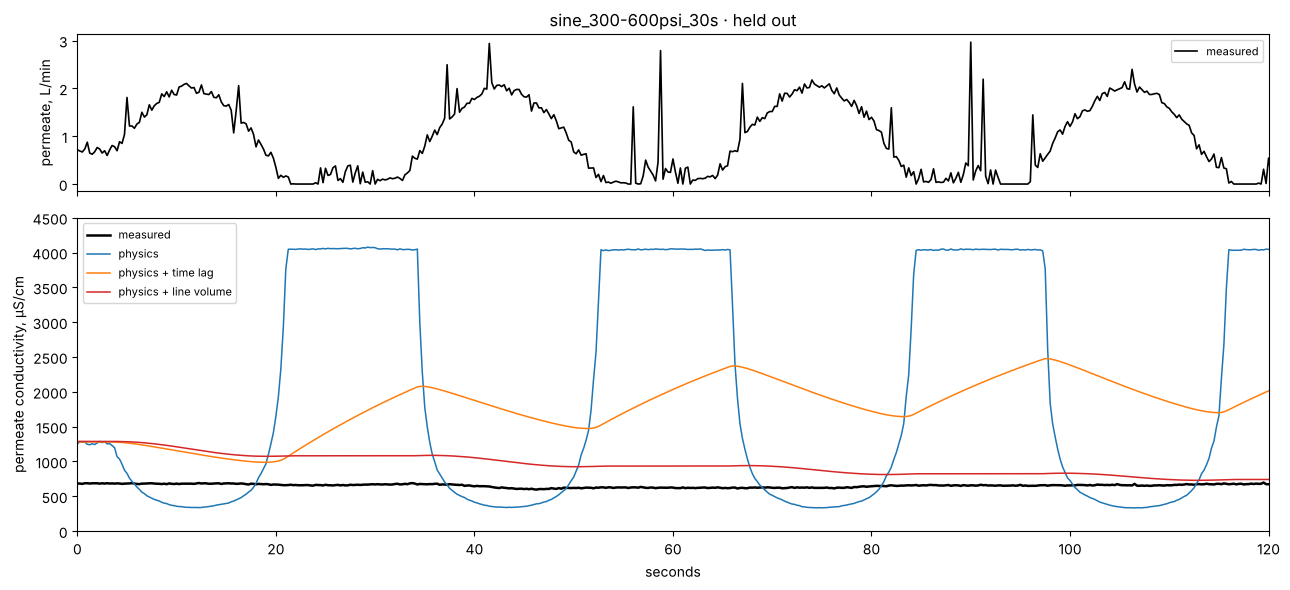

In [18]:
cols = [f"{r} · cond {s}" for r in ("period", "wec") for s in ("MAE", "R²")]
rows = [(i, m) for i in ("ours", "Smart RO's") for m in ("physics", "physics + time lag", "physics + line volume",
                                                       "hybrid", "hybrid + time lag", "hybrid + line volume")]
display(table12.loc[rows + [("Smart RO, as reported", "its model")], cols].round(3))
f = "sine_300-600psi_30s_period"
w = ((raw.file == f).to_numpy() & eligible)
tt = raw.t[w].to_numpy() - raw.t[w].min()
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
ax[0].plot(tt, q[w], "k", lw=1.2, label="measured"); ax[0].set_ylabel("permeate, L/min"); ax[0].legend(fontsize=8)
ax[1].plot(tt, k[w], "k", lw=1.8, label="measured")
for name, c in (("physics", "tab:blue"), ("physics + time lag", "tab:orange"), ("physics + line volume", "tab:red")):
    ax[1].plot(tt, preds_ours[name][1][w], lw=1.1, color=c, label=name)
ax[1].set_ylim(0, 4500); ax[1].set_xlim(0, 120); ax[1].set_xlabel("seconds"); ax[1].set_ylabel("permeate conductivity, µS/cm")
ax[0].set_title(f.replace("_period", "") + " · held out"); ax[1].legend(fontsize=8); plt.tight_layout()
trace = pd.DataFrame({"t": tt, "q_meas": q[w], "k_meas": k[w], **{name: preds_ours[name][1][w] for name in
                      ("physics", "physics + time lag", "physics + line volume", "hybrid", "hybrid + line volume")}})

In [19]:
# the same two forms on our own split (one-second rows; chosen on the training runs, scored where the element produces)
k1 = (x.c_p / K_SAL).to_numpy(); seg1 = x.seg.to_numpy()
qph1, Sph1 = predict_physics(x, A, B)
k_ph1 = np.where(qph1 * 60 / AREA >= FLUX_MIN, Sph1 / np.maximum(qph1, 1e-12), np.nan) / K_SAL
k_fill = pd.Series(k_ph1).groupby(seg1).ffill().bfill().to_numpy()   # hold the last producing value
prod1 = (x.flux >= FLUX_MIN).to_numpy(); m_tr = (x.split == "train").to_numpy() & prod1
GRID1 = [("time lag", tau, dl) for tau in (0, 1, 2, 4, 8, 16, 32, 64, 128) for dl in (0, 1, 2, 4)] + VOLUMES
mae1 = {c: float(np.mean(np.abs(sensor(k_fill, qph1, c, seg1, dt=1.0)[m_tr] - k1[m_tr]))) for c in GRID1}
lag1, vol1 = min(GRID1[:36], key=mae1.get), min(VOLUMES, key=mae1.get)
our_split = {"time lag: τ, dead time (s)": [lag1[1], lag1[2]], "line volume (L)": vol1[1]}
for name, mm in (("in range", (x.split == "test_in").to_numpy() & prod1), ("below range", (x.split == "test_low").to_numpy() & prod1)):
    our_split[name] = {"physics": metrics(k1[mm], k_fill[mm]),
                       "physics + time lag": metrics(k1[mm], sensor(k_fill, qph1, lag1, seg1, dt=1.0)[mm]),
                       "physics + line volume": metrics(k1[mm], sensor(k_fill, qph1, vol1, seg1, dt=1.0)[mm])}
print("chosen on the training runs:", {k_: v for k_, v in our_split.items() if "range" not in k_})
pd.DataFrame({(name, m): v for name in ("in range", "below range") for m, v in our_split[name].items()}).T.round(3)

chosen on the training runs: {'time lag: τ, dead time (s)': [32, 0], 'line volume (L)': 1.0}


MAE       R²
in range    physics                109.041   -0.624
            physics + time lag      90.684    0.046
            physics + line volume   95.569   -0.090
below range physics                761.860 -352.306
            physics + time lag     811.500 -221.378
            physics + line volume  195.052  -15.473

In [20]:
# everything sections 10-13 printed, in one file (the episode's pages read it)
import json
second_look = {
    "audit": {"rows": len(raw), "files": int(raw.file.nunique()), "conditions": int(raw.seg.nunique()),
              "reject_above_feed_share": float((gap > 0).mean()), "median_gap_psi": float(gap.median()),
              "steady_gap_psi": {str(int(round(p))): round(float(v), 2) for p, v in zip(steady.feed_psi, steady["reject − feed, psi"])},
              "balance_p95": float(np.quantile(np.abs(res) / raw.q_f, 0.95)), "zero_flow_rows": int((raw.q_p == 0).sum())},
    "gauge": {"A_both": A, "A_feed": A_feed, **{f"{name} · {m}": v for (name, m), v in cmp.items()}},
    "counts": counts, "spline": spline, "smart_ro_reported": SMART_RO, "sensors": sensors, "our_split": our_split,
    "fair": {f"{i} · {m}": v for (i, m), v in fair.items()},
}
Path("phase1_second_look.json").write_text(json.dumps(second_look, indent=1, ensure_ascii=False, default=float))
trace.iloc[::4].round(3).to_csv("phase1_second_look_trace.csv", index=False)
print("written phase1_second_look.json and phase1_second_look_trace.csv")

written phase1_second_look.json and phase1_second_look_trace.csv


## What it means

- **Water (production):** the **hybrid** is the model to use. Physics alone gives the right shape but runs low; XGBoost alone is close
  inside the pressure range it was trained on and fails below it, because a tree cannot extrapolate. Together they hold up in both.
- **Product salinity (quality):** the **physics** alone is the best here; the ML part does not improve it on unseen runs.
  All models miss the two sea-wave runs, whose permeate is saltier than their pressure suggests — not explained by this data.
- **Uncertainty:** the ranges estimated on the training runs are too narrow for new operating patterns. For planning,
  use the errors seen on the unseen runs (section 7), not the ones the model expects.
- **A second look, with Smart RO (sections 10–13):**
  - The reject gauge reads above the feed gauge in 99 % of the rows, by more at higher pressure: the two gauges disagree, and the
    data cannot say which is off. With the feed gauge alone, the answer does not change (the hybrid: 4.8 % in range, 1.8 % below).
  - Scored Smart RO's way, the result is mixed — each side wins two of four: Smart RO on the unseen period's water and, clearly,
    on the sea-wave salinity; our hybrid on the unseen period's salinity and on the sea-wave water, where a pressure-only curve
    beats both. Its held-out runs stay inside the pressures the models learned; the physics earns its place outside them
    (section 6b) and on a new waveform.
  - The conductivity probe reads the water in its line. Read through about 1 L of line, refreshed at the predicted flow, the
    physics' row-by-row error on the unseen period falls from 764 to 102 µS/cm (a fixed 32-s lag, Smart RO's form, gives 618).
    The line was tried after a first comparison (post hoc); its size was chosen on the development rows only.
    The sea-wave salinity is still not explained by this data.
- **Limits:** one element, NaCl water at ~20 °C, no fouling, no start-up or shut-down, no measured power, and two pressure gauges
  that disagree — the energy per m³ of a plant needs a stated plant model (recovery, energy recovery, pump efficiency). That is the next phase.